# Section 1: Import libraries and dataset

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

# The source CSV uses semicolons to separate columns. sep argument prevents formatting issues
dataset = pd.read_csv("data/bank-additional-full.csv", sep=";")

# Section 2: Exploratory Data Analysis

This section examines the records contained within the dataset, the distribution of customer outcomes after a subscription offer, and issues that will need attention before modelling. 

Each row contains customer information and a recorded marketing campaign outcome. Because the dataset does not include customer identifiers, we cannot confirm whether every row represents a different customer. 

Our target variable **y**, records whether a term deposit has been subscribed to. 

## 2.1 Dataset structure

First, check the table dimensions and a few records, then inspect the stored data types.
A numerical storage type does not guarantee that every value is an ordinary measurement;
special codes are investigated in Section 2.5.

In [27]:
#
n_records, n_columns = dataset.shape
print(f"Records: {n_records:,}")
print(f"Input variables: {n_columns - 1}")
print("Target: y (yes = subscribed, no = did not subscribe)")
dataset.head()

Records: 41,188
Input variables: 20
Target: y (yes = subscribed, no = did not subscribe)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

There are **41,188 records, 20 input variables and one target column**. The inputs contain
ten numerical variables and ten categorical variables. The target is categorical with two
possible outcomes, making this a binary classification problem. The file contains customer
attributes, campaign information, previous-campaign history, and economic indicators.

## 2.2 Missing information and repeated records

### Recognised nulls and explicit unknown categories

`isna()` is used to check for null values within the dataset. None are found. Instead, a category; "unknown" is found. Using `.eq()` we can count all instnaces of at least one unknown or blank within our rows 

we use pandas to create a new summary table for the amount of unknowns found and the percentage. Giving us insight into which input feature contains the majority percentage of unknowns

In [ ]:
null_counts = dataset.isna().sum()
unknown_counts = dataset.eq("unknown").sum()
blank_counts = dataset.eq("").sum()

print(f"Pandas-recognised null cells: {null_counts.sum():,}")
print(f"Empty-string cells: {blank_counts.sum():,}")
# creates a summary table for unknown values
unknown_summary = pd.DataFrame({
    "unknown_count": unknown_counts,
    "unknown_percent": unknown_counts / len(dataset) * 100,
})
# filter out rows without unknown values
unknown_summary = unknown_summary.loc[unknown_counts.gt(0)]
#sort in descending order of unknown count
unknown_summary = unknown_summary.sort_values("unknown_count", ascending=False)
# display the summary table rounded to 2 decimal places
display(unknown_summary.round(2))

has_unknown = dataset.eq("unknown").any(axis=1)
print(f"Records with at least one unknown: {has_unknown.sum():,} "
      f"({has_unknown.mean():.2%})")

Pandas-recognised null cells: 0
Empty-string cells: 0
Records with at least one unknown: 10,700 (25.98%)


,unknown_count,unknown_percent
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19


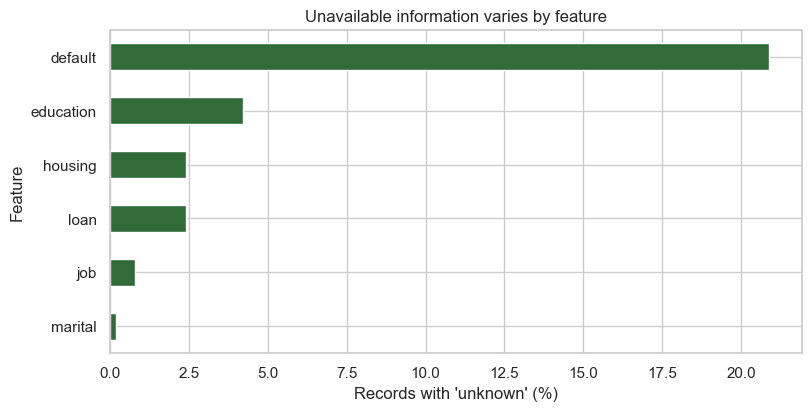

In [ ]:
sns.set_theme(style="whitegrid", context="notebook")
# two variables fig and ax are created for the plot
# 8 inches wide and 4 inches tall
# adjusted layout for better spacing without overlapping
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
#barh = horizontal barchart. 
unknown_summary["unknown_percent"].sort_values().plot.barh(
    ax=ax, color="#316B3A"
)
ax.set(title="Unavailable information varies by feature",
       xlabel="Records with 'unknown' (%)", ylabel="Feature")
plt.show()


Removing every record with any unknown would discard **10,700 records (25.98%)**, including
their known features and subscription outcomes. To examine what that deletion would change,
the following chart compares subscription rates for the groups already investigated during the initial exploration.

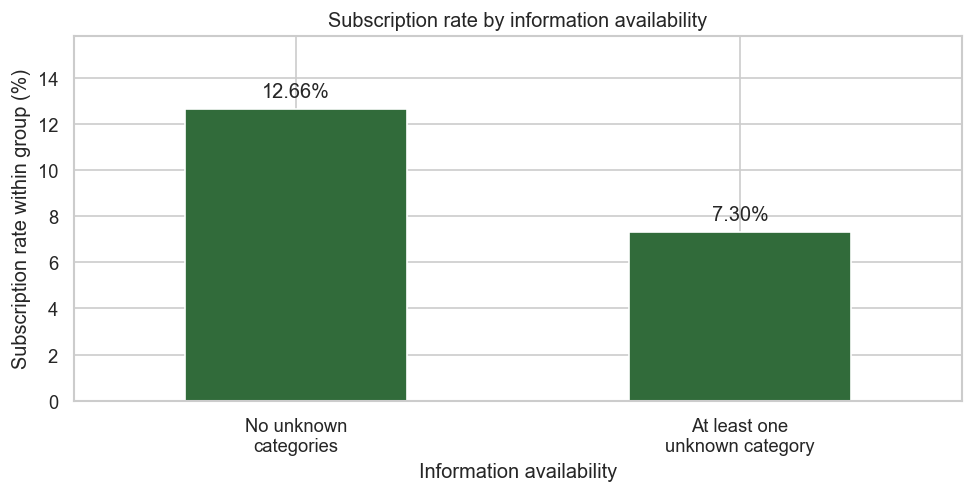

In [ ]:
#convert true or false to descriptive labels
unknown_groups = has_unknown.map({
    False: "No unknown categories",
    True: "At least one unknown category",
})
# crosstab to compare unknown/subscribed relationship
group_counts = pd.crosstab(unknown_groups, dataset["y"])
group_rates = pd.crosstab(unknown_groups, dataset["y"], normalize="index") * 100
unknown_comparison = pd.DataFrame({
    "records": group_counts.sum(axis=1),
    "subscribed": group_counts["yes"],
    "subscription_percent": group_rates["yes"],
})
unknown_comparison.index.name = "Information availability"
# Plot the subscription percentage within each group.
subscription_rates = unknown_comparison["subscription_percent"].reindex([
    "No unknown categories",
    "At least one unknown category",
])

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
subscription_rates.plot.bar(ax=ax, color="#316B3A", rot=0)

# Add the percentage above each bar, with space between the bar and text.
ax.bar_label(
    ax.containers[0],
    labels=[f"{rate:.2f}%" for rate in subscription_rates],
    padding=5,
)
ax.set(
    title="Subscription rate by information availability",
    xlabel="Information availability",
    ylabel="Subscription rate within group (%)",
    ylim=(0, subscription_rates.max() * 1.25),
)
ax.set_xticks([0, 1], labels=[
    "No unknown\ncategories",
    "At least one\nunknown category",
])
plt.show()

The subscription rate is 12.66% among records without unknown categories and 7.30%
among records with at least one. Removing rows with at least one unknown would remove almost 26% of our data, where rows still contain useful information. There could also be an opportunity for the model to learn from the fact that records containing at least one unknown are associated with a lower observed subscription rate in this dataset. Therefore unknown will be treated as a seperate category and records shall be retained


# **Secion3: Data Preprocessing and Cleaning**

# **Section4: Model Training**

# **Section5: Model Evaluation**

# Advanced
# **Section6: Module Hypertuning**